In [1]:

import torch
import numpy as np
import random
import torchvision
import matplotlib.pyplot as plt

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


In [3]:
#Loading the dataset


from torchvision import datasets

train_dataset = datasets.CIFAR10(
    root="/content/data",
    train=True,
    download=True
)

test_dataset = datasets.CIFAR10(
    root="/content/data",
    train=False,
    download=True
)

X_all = np.array(train_dataset.data)
y_all = np.array(train_dataset.targets)

X_test = np.array(test_dataset.data)
y_test = np.array(test_dataset.targets)

class_names = train_dataset.classes

print("Original training images:", X_all.shape)
print("Original test images:", X_test.shape)
print("Classes:", class_names)


100%|██████████| 170M/170M [28:27<00:00, 99.9kB/s]


Original training images: (50000, 32, 32, 3)
Original test images: (10000, 32, 32, 3)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [4]:

rng = np.random.default_rng(SEED)

selected_indices = []

for class_id in range(10):
    indices = np.where(y_all == class_id)[0]
    selected = rng.choice(indices, size=50, replace=False)
    selected_indices.extend(selected)

selected_indices = np.array(selected_indices)
rng.shuffle(selected_indices)

X_small = X_all[selected_indices]
y_small = y_all[selected_indices]

train_indices = []
val_indices = []

for class_id in range(10):
    indices = np.where(y_small == class_id)[0]
    rng.shuffle(indices)

    train_indices.extend(indices[:40])
    val_indices.extend(indices[40:])

train_indices = np.array(train_indices)
val_indices = np.array(val_indices)

X_train = X_small[train_indices]
y_train = y_small[train_indices]

X_val = X_small[val_indices]
y_val = y_small[val_indices]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Clean test:", X_test.shape, y_test.shape)

print("\nTraining images per class:")
print(np.bincount(y_train, minlength=10))

print("\nValidation images per class:")
print(np.bincount(y_val, minlength=10))


Training: (400, 32, 32, 3) (400,)
Validation: (100, 32, 32, 3) (100,)
Clean test: (10000, 32, 32, 3) (10000,)

Training images per class:
[40 40 40 40 40 40 40 40 40 40]

Validation images per class:
[10 10 10 10 10 10 10 10 10 10]


In [5]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class InceptionModule(nn.Module):
    def __init__(self, in_channels):
        super().__init__()

        # Branch 1: 1x1 convolution
        self.branch1 = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True)
        )

        # Branch 2: 1x1 reduction + 3x3 convolution
        self.branch2 = nn.Sequential(
            nn.Conv2d(in_channels, 12, kernel_size=1),
            nn.BatchNorm2d(12),
            nn.ReLU(inplace=True),
            nn.Conv2d(12, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True)
        )

        # Branch 3: 1x1 reduction + 5x5 convolution
        self.branch3 = nn.Sequential(
            nn.Conv2d(in_channels, 8, kernel_size=1),
            nn.BatchNorm2d(8),
            nn.ReLU(inplace=True),
            nn.Conv2d(8, 12, kernel_size=5, padding=2),
            nn.BatchNorm2d(12),
            nn.ReLU(inplace=True)
        )

        # Branch 4: Average pooling + 1x1 convolution
        self.branch4 = nn.Sequential(
            nn.AvgPool2d(kernel_size=3, stride=1, padding=1),
            nn.Conv2d(in_channels, 8, kernel_size=1),
            nn.BatchNorm2d(8),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        b4 = self.branch4(x)

        # Combine all parallel branches
        return torch.cat([b1, b2, b3, b4], dim=1)


In [6]:

class SmallInceptionCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # Initial feature extraction
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        # First Inception module: 32 -> 52 channels
        self.inception1 = InceptionModule(32)

        # Reduce spatial dimensions: 32x32 -> 16x16
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Second Inception module: 52 -> 52 channels
        self.inception2 = InceptionModule(52)

        # Convert feature maps into a 1x1 spatial representation
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Dropout before final classifier
        self.dropout = nn.Dropout(p=0.3)

        # 52 features -> 10 CIFAR-10 classes
        self.classifier = nn.Linear(52, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.inception1(x)
        x = self.pool(x)
        x = self.inception2(x)

        x = self.global_pool(x)
        x = torch.flatten(x, 1)

        x = self.dropout(x)
        x = self.classifier(x)

        return x


model = SmallInceptionCNN().to(device)

print(model)


SmallInceptionCNN(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (inception1): InceptionModule(
    (branch1): Sequential(
      (0): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (branch2): Sequential(
      (0): Conv2d(32, 12, kernel_size=(1, 1), stride=(1, 1))
      (1): BatchNorm2d(12, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(12, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
    (branch3): Sequential(
      (0): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
      (1): Batch

In [7]:

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Within 1M limit:", trainable_params <= 1_000_000)

# Check output shape
dummy_input = torch.randn(2, 3, 32, 32).to(device)

model.eval()
with torch.no_grad():
    output = model(dummy_input)

print("Output shape:", output.shape)


Total parameters: 13,874
Trainable parameters: 13,874
Within 1M limit: True
Output shape: torch.Size([2, 10])


In [8]:

from torch.utils.data import TensorDataset, DataLoader

# Convert HWC images to CHW tensors and normalize to [0, 1]
X_train_tensor = torch.tensor(
    X_train.copy()
).permute(0, 3, 1, 2).float() / 255.0

X_val_tensor = torch.tensor(
    X_val.copy()
).permute(0, 3, 1, 2).float() / 255.0

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

train_tensor_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

val_tensor_dataset = TensorDataset(
    X_val_tensor, y_val_tensor
)

train_loader = DataLoader(
    train_tensor_dataset,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

val_loader = DataLoader(
    val_tensor_dataset,
    batch_size=32,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Training tensor:", X_train_tensor.shape)


Training batches: 13
Validation batches: 4
Training tensor: torch.Size([400, 3, 32, 32])


In [10]:
#Part A


import copy
import matplotlib.pyplot as plt
import torch.nn as nn

# Reproducible initialization for baseline
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model = SmallInceptionCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4
)

MAX_EPOCHS = 60
PATIENCE = 10

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print("Baseline configuration ready.")
print("Device:", device)
print("Maximum epochs:", MAX_EPOCHS)


Baseline configuration ready.
Device: cuda
Maximum epochs: 60


In [11]:

for epoch in range(MAX_EPOCHS):

    # ---------------- TRAINING ----------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # ---------------- VALIDATION ----------------
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_loss / total
    val_acc = 100 * correct / total

    # Record learning curves
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # Update learning rate using validation loss
    scheduler.step(val_loss)

    # Save best model using validation data only
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch [{epoch+1:02d}/{MAX_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

# Restore the best validation checkpoint
model.load_state_dict(best_model_state)

torch.save(model.state_dict(), "/content/baseline_model.pth")

print("\nBaseline training complete.")
print("Best validation loss:", round(best_val_loss, 4))
print("Best checkpoint saved.")


Epoch [01/60] Train Loss: 2.3110 | Train Acc: 12.25% | Val Loss: 2.3048 | Val Acc: 10.00%
Epoch [02/60] Train Loss: 2.1550 | Train Acc: 24.25% | Val Loss: 2.2879 | Val Acc: 16.00%
Epoch [03/60] Train Loss: 2.0917 | Train Acc: 26.75% | Val Loss: 2.1884 | Val Acc: 23.00%
Epoch [04/60] Train Loss: 2.0078 | Train Acc: 34.50% | Val Loss: 2.0830 | Val Acc: 25.00%
Epoch [05/60] Train Loss: 1.9671 | Train Acc: 29.25% | Val Loss: 2.0206 | Val Acc: 25.00%
Epoch [06/60] Train Loss: 1.9344 | Train Acc: 34.00% | Val Loss: 2.0138 | Val Acc: 28.00%
Epoch [07/60] Train Loss: 1.8728 | Train Acc: 34.75% | Val Loss: 1.9824 | Val Acc: 25.00%
Epoch [08/60] Train Loss: 1.8655 | Train Acc: 36.25% | Val Loss: 1.9422 | Val Acc: 27.00%
Epoch [09/60] Train Loss: 1.8357 | Train Acc: 36.50% | Val Loss: 1.9833 | Val Acc: 28.00%
Epoch [10/60] Train Loss: 1.7890 | Train Acc: 35.00% | Val Loss: 1.9096 | Val Acc: 34.00%
Epoch [11/60] Train Loss: 1.7745 | Train Acc: 36.00% | Val Loss: 1.9016 | Val Acc: 28.00%
Epoch [12/

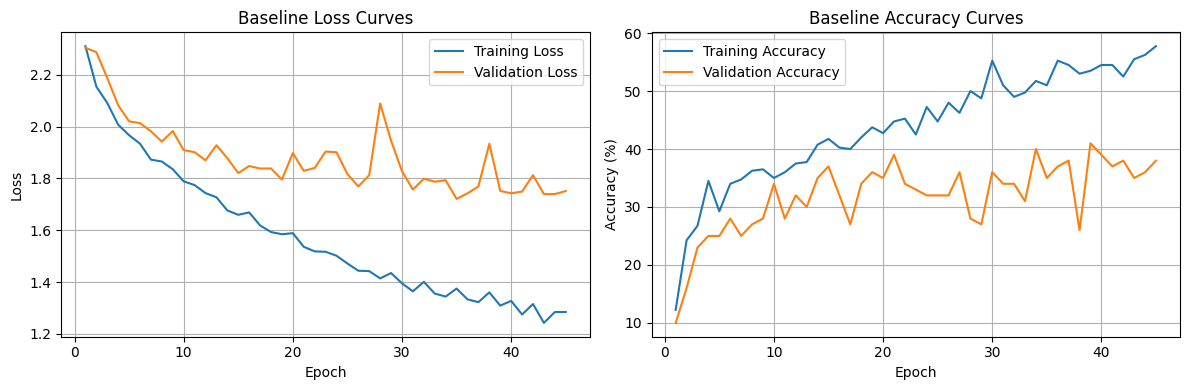

In [12]:

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline Loss Curves")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_acc"], label="Training Accuracy")
plt.plot(epochs, history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Baseline Accuracy Curves")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [13]:

def evaluate_loader(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100.0 * correct / total


train_acc_final = evaluate_loader(model, train_loader)
val_acc_final = evaluate_loader(model, val_loader)

print(f"Baseline Training Accuracy: {train_acc_final:.2f}%")
print(f"Baseline Validation Accuracy: {val_acc_final:.2f}%")


Baseline Training Accuracy: 62.25%
Baseline Validation Accuracy: 35.00%


In [14]:

from torch.utils.data import TensorDataset, DataLoader

# Convert clean test images to PyTorch tensors
X_test_tensor = torch.tensor(
    X_test.copy()
).permute(0, 3, 1, 2).float() / 255.0

y_test_tensor = torch.tensor(y_test, dtype=torch.long)

clean_test_loader = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=128,
    shuffle=False
)

# Evaluate the saved best baseline model
model.load_state_dict(
    torch.load("/content/baseline_model.pth", map_location=device)
)
model.eval()

clean_test_acc = evaluate_loader(model, clean_test_loader)

print(f"Baseline Training Accuracy: {train_acc_final:.2f}%")
print(f"Baseline Validation Accuracy: {val_acc_final:.2f}%")
print(f"Baseline Clean-Test Accuracy: {clean_test_acc:.2f}%")
print("Baseline Shifted-Test Accuracy: Not available yet")


Baseline Training Accuracy: 62.25%
Baseline Validation Accuracy: 35.00%
Baseline Clean-Test Accuracy: 37.12%
Baseline Shifted-Test Accuracy: Not available yet


In [15]:

from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# Augmentation is applied dynamically to training images only
train_transform = transforms.Compose([
    transforms.ToPILImage(),

    # Random crop and translation
    transforms.RandomCrop(32, padding=4),

    # Left-right flip
    transforms.RandomHorizontalFlip(p=0.5),

    # Rotation up to +/- 25 degrees
    transforms.RandomRotation(degrees=25),

    # Brightness, contrast and saturation changes
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),

    # Sometimes blur the image
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
    ], p=0.2),

    # Convert to tensor with values in [0, 1]
    transforms.ToTensor()
])

# Validation and test images remain unchanged
eval_transform = transforms.Compose([
    transforms.ToTensor()
])

print("Training augmentation pipeline created.")


Training augmentation pipeline created.


In [16]:

class CIFARSmallDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = self.images[index]
        label = int(self.labels[index])

        if self.transform is not None:
            image = self.transform(image)

        return image, label


augmented_train_dataset = CIFARSmallDataset(
    X_train,
    y_train,
    transform=train_transform
)

augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=32,
    shuffle=True
)

print("Original training images:", len(X_train))
print("Augmented dataset length:", len(augmented_train_dataset))


Original training images: 400
Augmented dataset length: 400


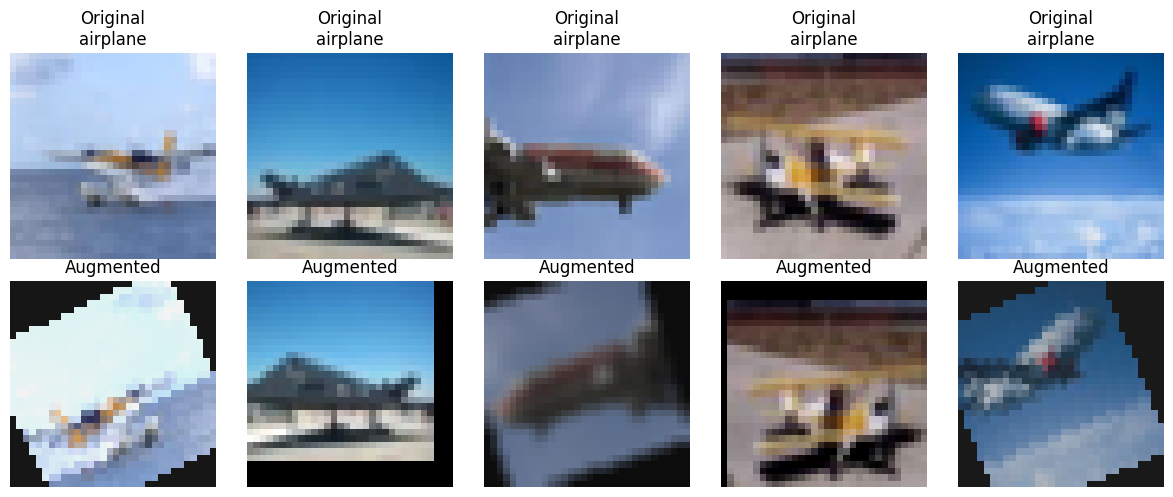

In [17]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(5):
    # Original image
    original = X_train[i]

    # A randomly augmented version
    augmented, label = augmented_train_dataset[i]

    axes[0, i].imshow(original)
    axes[0, i].set_title(
        f"Original\n{class_names[y_train[i]]}"
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(augmented.permute(1, 2, 0).numpy())
    axes[1, i].set_title("Augmented")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()


1. Vertical flip: Aksar harmful ya less useful ho sakta hai, kyun ke CIFAR-10 ke cars, ships aur animals upside-down orientation mein unnatural ho sakte hain.
2. Rotation ±90°: Zyada orientation diversity milti hai, lekin unrealistic examples model ko confuse kar sakti hain. ±25° target ke liye ±90° excessive ho sakta hai.
3. Too much augmentation: Sirf 500 images aur limited-capacity model ke liye overly distorted images useful features seekhna mushkil bana sakti hain, jis se underfitting aur accuracy loss ho sakta hai.
Ab tum Step 9 se Step 11 tak cells run karo. Mujhe clean-test accuracy aur augmented images ka outp

In [18]:

# Fix seed for this experiment
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

aug_model = SmallInceptionCNN().to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

optimizer = torch.optim.AdamW(
    aug_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4
)

MAX_EPOCHS = 60
PATIENCE = 10

best_val_loss = float("inf")
best_aug_state = None
wait = 0

aug_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print("Augmented model initialized.")
print("Trainable parameters:",
      sum(p.numel() for p in aug_model.parameters()
          if p.requires_grad))


Augmented model initialized.
Trainable parameters: 13874


In [19]:

for epoch in range(MAX_EPOCHS):

    # Training
    aug_model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in augmented_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = aug_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / total
    train_acc = 100.0 * correct / total

    # Validation: no augmentation
    aug_model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = aug_model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    val_loss = total_loss / total
    val_acc = 100.0 * correct / total

    aug_history["train_loss"].append(train_loss)
    aug_history["val_loss"].append(val_loss)
    aug_history["train_acc"].append(train_acc)
    aug_history["val_acc"].append(val_acc)

    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_aug_state = copy.deepcopy(aug_model.state_dict())
        wait = 0
    else:
        wait += 1

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if wait >= PATIENCE:
        print("Early stopping.")
        break

aug_model.load_state_dict(best_aug_state)
torch.save(aug_model.state_dict(), "/content/augmented_model.pth")

print("Augmented training completed.")


Epoch 01 | Train Acc: 11.50% | Val Acc: 10.00% | Train Loss: 2.3024 | Val Loss: 2.3049
Epoch 02 | Train Acc: 17.25% | Val Acc: 11.00% | Train Loss: 2.2263 | Val Loss: 2.2790
Epoch 03 | Train Acc: 21.00% | Val Acc: 17.00% | Train Loss: 2.1517 | Val Loss: 2.1797
Epoch 04 | Train Acc: 23.75% | Val Acc: 23.00% | Train Loss: 2.1144 | Val Loss: 2.0923
Epoch 05 | Train Acc: 21.50% | Val Acc: 30.00% | Train Loss: 2.0822 | Val Loss: 2.0436
Epoch 06 | Train Acc: 27.25% | Val Acc: 30.00% | Train Loss: 2.0425 | Val Loss: 2.0475
Epoch 07 | Train Acc: 26.00% | Val Acc: 25.00% | Train Loss: 2.0272 | Val Loss: 1.9980
Epoch 08 | Train Acc: 25.75% | Val Acc: 26.00% | Train Loss: 2.0120 | Val Loss: 2.0142
Epoch 09 | Train Acc: 31.75% | Val Acc: 19.00% | Train Loss: 1.9837 | Val Loss: 2.0445
Epoch 10 | Train Acc: 28.00% | Val Acc: 29.00% | Train Loss: 1.9899 | Val Loss: 1.9772
Epoch 11 | Train Acc: 29.50% | Val Acc: 29.00% | Train Loss: 1.9694 | Val Loss: 1.9499
Epoch 12 | Train Acc: 30.00% | Val Acc: 34.

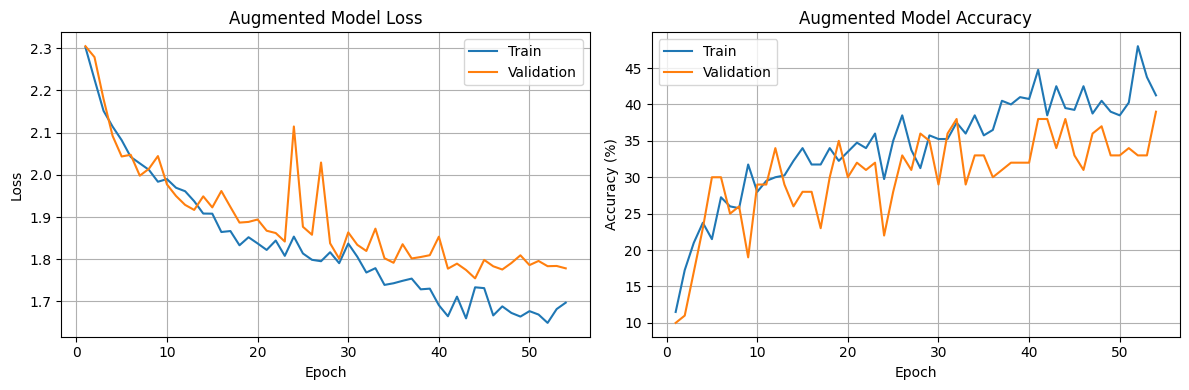

In [20]:

epochs = range(1, len(aug_history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, aug_history["train_loss"], label="Train")
plt.plot(epochs, aug_history["val_loss"], label="Validation")
plt.title("Augmented Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, aug_history["train_acc"], label="Train")
plt.plot(epochs, aug_history["val_acc"], label="Validation")
plt.title("Augmented Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [21]:

baseline_best_val = max(history["val_acc"])
augmented_best_val = max(aug_history["val_acc"])

print(f"Baseline best validation accuracy: {baseline_best_val:.2f}%")
print(f"Augmented best validation accuracy: {augmented_best_val:.2f}%")
print(
    "Validation accuracy change:",
    f"{augmented_best_val - baseline_best_val:+.2f} percentage points"
)


Baseline best validation accuracy: 41.00%
Augmented best validation accuracy: 39.00%
Validation accuracy change: -2.00 percentage points


In [24]:

# Load the selected augmented checkpoint
aug_model.load_state_dict(
    torch.load(
        "/content/augmented_model.pth",
        map_location=device,
        weights_only=True
    )
)

aug_model.eval()

# Evaluate original, unaugmented training images
aug_train_acc = evaluate_loader(aug_model, train_loader)

# Evaluate validation images
aug_val_acc = evaluate_loader(aug_model, val_loader)

# Evaluate clean CIFAR-10 test images
aug_clean_test_acc = evaluate_loader(
    aug_model, clean_test_loader
)

print("AUGMENTED MODEL — SELECTED CHECKPOINT")
print(f"Training Accuracy:   {aug_train_acc:.2f}%")
print(f"Validation Accuracy: {aug_val_acc:.2f}%")
print(f"Clean-Test Accuracy: {aug_clean_test_acc:.2f}%")


AUGMENTED MODEL — SELECTED CHECKPOINT
Training Accuracy:   52.25%
Validation Accuracy: 38.00%
Clean-Test Accuracy: 34.90%


### B. Data Augmentation Justification

**1. Why use horizontal flipping but not vertical flipping?**

Horizontal flipping creates realistic variations in object orientation and helps the model generalize. Vertical flipping can produce unrealistic upside-down images of cars, ships, and animals, so it may be less useful for CIFAR-10.

**2. Why use rotations of ±25° instead of ±90°?**

Rotations of ±25° introduce moderate orientation changes that are more consistent with the expected corruption. Rotations of ±90° can create unrealistic examples and may make learning harder.

**3. Why can excessive augmentation hurt performance?**

Excessive augmentation may distort important visual features or create unrealistic images. With only 400 training images, overly strong augmentation can make learning difficult and reduce validation accuracy.

In [25]:

import os

print("Baseline checkpoint exists:",
      os.path.exists("/content/baseline_model.pth"))

print("Augmented checkpoint exists:",
      os.path.exists("/content/augmented_model.pth"))

print("Trainable parameters:",
      sum(p.numel() for p in aug_model.parameters()
          if p.requires_grad))

print("Maximum allowed parameters: 1,000,000")


Baseline checkpoint exists: True
Augmented checkpoint exists: True
Trainable parameters: 13874
Maximum allowed parameters: 1,000,000


In [26]:

from torchvision import transforms
from torch.utils.data import DataLoader

# Geometric transformations only
geometric_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=25),
    transforms.ToTensor()
])

# Photometric transformations only
photometric_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),
    transforms.RandomApply([
        transforms.GaussianBlur(
            kernel_size=3,
            sigma=(0.1, 1.0)
        )
    ], p=0.2),
    transforms.ToTensor()
])

# Combined geometric + photometric transformations
combined_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=25),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),
    transforms.RandomApply([
        transforms.GaussianBlur(
            kernel_size=3,
            sigma=(0.1, 1.0)
        )
    ], p=0.2),
    transforms.ToTensor()
])

print("Geometric, photometric and combined pipelines created.")


Geometric, photometric and combined pipelines created.


In [27]:

import copy
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

def run_experiment(transform, seed=42, label_smoothing=0.0,
                   use_cutout=False, epochs=40):

    # Set seeds
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Optional Random Erasing after tensor conversion
    if use_cutout:
        experiment_transform = transforms.Compose([
            transform,
            transforms.RandomErasing(
                p=0.5,
                scale=(0.10, 0.25),
                ratio=(0.5, 2.0),
                value=0
            )
        ])
    else:
        experiment_transform = transform

    dataset = CIFARSmallDataset(
        X_train, y_train, transform=experiment_transform
    )

    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    experiment_model = SmallInceptionCNN().to(device)

    criterion = nn.CrossEntropyLoss(
        label_smoothing=label_smoothing
    )

    optimizer = torch.optim.AdamW(
        experiment_model.parameters(),
        lr=0.001,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=3
    )

    best_loss = float("inf")
    best_state = copy.deepcopy(experiment_model.state_dict())
    best_val_acc = 0.0
    wait = 0
    patience = 7

    for epoch in range(epochs):
        experiment_model.train()

        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = experiment_model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        # Validation
        experiment_model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = experiment_model(images)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * labels.size(0)
                val_correct += (
                    outputs.argmax(1) == labels
                ).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = 100.0 * val_correct / val_total
        scheduler.step(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(
                experiment_model.state_dict()
            )
            best_val_acc = val_acc
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            break

    experiment_model.load_state_dict(best_state)

    return {
        "model": experiment_model,
        "val_acc": best_val_acc,
        "val_loss": best_loss
    }

print("Reusable experiment function created.")


Reusable experiment function created.


In [28]:

ablation_preview = {}

configs = {
    "Geometric only": geometric_transform,
    "Photometric only": photometric_transform,
    "Geometric + Photometric": combined_transform
}

for name, transform in configs.items():
    print(f"\nRunning: {name}")

    result = run_experiment(
        transform=transform,
        seed=42,
        label_smoothing=0.0,
        use_cutout=False,
        epochs=40
    )

    ablation_preview[name] = result

    print(
        f"{name} — Selected validation accuracy: "
        f"{result['val_acc']:.2f}%"
    )

print("\nPreview complete. These are single-seed results.")



Running: Geometric only
Geometric only — Selected validation accuracy: 37.00%

Running: Photometric only
Photometric only — Selected validation accuracy: 42.00%

Running: Geometric + Photometric
Geometric + Photometric — Selected validation accuracy: 38.00%

Preview complete. These are single-seed results.


In [29]:

print("Running photometric-only + Random Erasing...")

photometric_cutout_result = run_experiment(
    transform=photometric_transform,
    seed=42,
    label_smoothing=0.0,
    use_cutout=True,
    epochs=40
)

print(
    "Photometric + Random Erasing validation accuracy: "
    f"{photometric_cutout_result['val_acc']:.2f}%"
)


Running photometric-only + Random Erasing...
Photometric + Random Erasing validation accuracy: 38.00%


In [30]:

print("Running photometric-only + label smoothing...")

photometric_smoothing_result = run_experiment(
    transform=photometric_transform,
    seed=42,
    label_smoothing=0.05,
    use_cutout=False,
    epochs=40
)

print(
    "Photometric + Label Smoothing validation accuracy: "
    f"{photometric_smoothing_result['val_acc']:.2f}%"
)


Running photometric-only + label smoothing...
Photometric + Label Smoothing validation accuracy: 43.00%


In [31]:



preview_results = {
    "Geometric only": ablation_preview["Geometric only"]["val_acc"],
    "Photometric only": ablation_preview["Photometric only"]["val_acc"],
    "Geometric + Photometric": ablation_preview[
        "Geometric + Photometric"
    ]["val_acc"],
    "Photometric + Random Erasing":
        photometric_cutout_result["val_acc"],
    "Photometric + Label Smoothing":
        photometric_smoothing_result["val_acc"]
}

print("PRELIMINARY RESULTS — SINGLE SEED")
print("-" * 48)

for name, accuracy in preview_results.items():
    print(f"{name:32s}: {accuracy:.2f}%")

best_name = max(preview_results, key=preview_results.get)
print("\nBest preliminary configuration:", best_name)


PRELIMINARY RESULTS — SINGLE SEED
------------------------------------------------
Geometric only                  : 37.00%
Photometric only                : 42.00%
Geometric + Photometric         : 38.00%
Photometric + Random Erasing    : 38.00%
Photometric + Label Smoothing   : 43.00%

Best preliminary configuration: Photometric + Label Smoothing


In [32]:
import numpy as np
import torch
import torch.nn as nn

def train_with_mixup(seed=42, alpha=0.2, epochs=40):
    import random

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    dataset = CIFARSmallDataset(
        X_train, y_train,
        transform=photometric_transform
    )

    generator = torch.Generator().manual_seed(seed)

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    model = SmallInceptionCNN().to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.5, patience=3
    )

    criterion = nn.CrossEntropyLoss()
    best_val_loss = float("inf")
    best_val_acc = 0.0
    best_state = None
    patience = 7
    wait = 0

    for epoch in range(epochs):
        model.train()

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            lam = np.random.beta(alpha, alpha)
            index = torch.randperm(images.size(0), device=device)

            mixed_images = (
                lam * images +
                (1 - lam) * images[index]
            )

            labels_a = labels
            labels_b = labels[index]

            optimizer.zero_grad()
            outputs = model(mixed_images)

            loss = (
                lam * criterion(outputs, labels_a) +
                (1 - lam) * criterion(outputs, labels_b)
            )

            loss.backward()
            optimizer.step()

        model.eval()
        total_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                total_loss += loss.item() * labels.size(0)
                correct += (
                    outputs.argmax(1) == labels
                ).sum().item()
                total += labels.size(0)

        val_loss = total_loss / total
        val_acc = 100.0 * correct / total
        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_val_acc = val_acc
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            break

    model.load_state_dict(best_state)
    model.to(device)

    return {
        "model": model,
        "val_acc": best_val_acc,
        "val_loss": best_val_loss
    }

In [33]:
mixup_result = train_with_mixup(
    seed=42,
    alpha=0.2,
    epochs=40
)

print(
    "Photometric + Mixup Validation Accuracy:",
    f"{mixup_result['val_acc']:.2f}%"
)

Photometric + Mixup Validation Accuracy: 43.00%


In [34]:

import random
import numpy as np
import torch
import torch.nn as nn

def train_with_cutmix(seed=42, alpha=1.0, epochs=40):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    dataset = CIFARSmallDataset(
        X_train, y_train,
        transform=photometric_transform
    )

    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(
        dataset, batch_size=32,
        shuffle=True, generator=generator
    )

    model = SmallInceptionCNN().to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=0.001,
        weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.5, patience=3
    )
    criterion = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_val_acc = 0.0
    best_state = None
    wait = 0

    for epoch in range(epochs):
        model.train()

        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            index = torch.randperm(images.size(0), device=device)

            lam = np.random.beta(alpha, alpha)
            _, _, height, width = images.shape

            cut_ratio = np.sqrt(1.0 - lam)
            cut_w = int(width * cut_ratio)
            cut_h = int(height * cut_ratio)

            cx = np.random.randint(width)
            cy = np.random.randint(height)

            x1 = max(cx - cut_w // 2, 0)
            x2 = min(cx + cut_w // 2, width)
            y1 = max(cy - cut_h // 2, 0)
            y2 = min(cy + cut_h // 2, height)

            cutmix_images = images.clone()
            cutmix_images[:, :, y1:y2, x1:x2] = (
                images[index, :, y1:y2, x1:x2]
            )

            # Actual lambda based on the replaced area
            lam = 1.0 - (
                (x2 - x1) * (y2 - y1) / (width * height)
            )

            optimizer.zero_grad()
            outputs = model(cutmix_images)

            loss = (
                lam * criterion(outputs, labels) +
                (1 - lam) * criterion(outputs, labels[index])
            )
            loss.backward()
            optimizer.step()

        model.eval()
        total_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                total_loss += loss.item() * labels.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)

        val_loss = total_loss / total
        val_acc = 100.0 * correct / total
        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_val_acc = val_acc
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1

        if wait >= 7:
            break

    model.load_state_dict(best_state)
    model.to(device)

    return {
        "model": model,
        "val_acc": best_val_acc,
        "val_loss": best_val_loss
    }


In [35]:

cutmix_result = train_with_cutmix(
    seed=42,
    alpha=1.0,
    epochs=40
)

print(
    "Photometric + CutMix Validation Accuracy:",
    f"{cutmix_result['val_acc']:.2f}%"
)


Photometric + CutMix Validation Accuracy: 35.00%


In [36]:

import numpy as np
import pandas as pd

SEEDS = [42, 123, 2026]

ablation_configs = {
    "Geometric only": {
        "transform": geometric_transform,
        "label_smoothing": 0.0,
        "use_cutout": False
    },
    "Photometric only": {
        "transform": photometric_transform,
        "label_smoothing": 0.0,
        "use_cutout": False
    },
    "Geometric + Photometric": {
        "transform": combined_transform,
        "label_smoothing": 0.0,
        "use_cutout": False
    },
    "Photometric + Random Erasing": {
        "transform": photometric_transform,
        "label_smoothing": 0.0,
        "use_cutout": True
    },
    "Photometric + Label Smoothing": {
        "transform": photometric_transform,
        "label_smoothing": 0.05,
        "use_cutout": False
    }
}

ablation_results = []

for config_name, config in ablation_configs.items():
    print(f"\nRunning: {config_name}")

    for seed in SEEDS:
        result = run_experiment(
            transform=config["transform"],
            seed=seed,
            label_smoothing=config["label_smoothing"],
            use_cutout=config["use_cutout"],
            epochs=40
        )

        ablation_results.append({
            "Configuration": config_name,
            "Seed": seed,
            "Validation Accuracy (%)": result["val_acc"]
        })

        print(
            f"Seed {seed}: "
            f"{result['val_acc']:.2f}%"
        )

print("\nAll experiments completed.")



Running: Geometric only
Seed 42: 37.00%
Seed 123: 34.00%
Seed 2026: 34.00%

Running: Photometric only
Seed 42: 40.00%
Seed 123: 42.00%
Seed 2026: 33.00%

Running: Geometric + Photometric
Seed 42: 37.00%
Seed 123: 36.00%
Seed 2026: 35.00%

Running: Photometric + Random Erasing
Seed 42: 40.00%
Seed 123: 37.00%
Seed 2026: 30.00%

Running: Photometric + Label Smoothing
Seed 42: 42.00%
Seed 123: 41.00%
Seed 2026: 33.00%

All experiments completed.


In [37]:

import pandas as pd

# Save individual seed results
results_df = pd.DataFrame(ablation_results)
results_df.to_csv(
    "/content/ablation_seed_results.csv",
    index=False
)

# Calculate mean and standard deviation
summary_df = (
    results_df
    .groupby("Configuration")["Validation Accuracy (%)"]
    .agg(["mean", "std"])
    .reset_index()
)

summary_df["Mean ± Std (%)"] = summary_df.apply(
    lambda row: f"{row['mean']:.2f} ± {row['std']:.2f}",
    axis=1
)

summary_df.to_csv(
    "/content/ablation_summary.csv",
    index=False
)

print("Individual results saved.")
print("Summary results saved.")
display(summary_df[["Configuration", "Mean ± Std (%)"]])


Individual results saved.
Summary results saved.


,Configuration,Mean ± Std (%)
0,Geometric + Photometric,36.00 ± 1.00
1,Geometric only,35.00 ± 1.73
2,Photometric + Label Smoothing,38.67 ± 4.93
3,Photometric + Random Erasing,35.67 ± 5.13
4,Photometric only,38.33 ± 4.73


In [39]:

def train_with_mixup_smoothing(
    seed=42, alpha=0.2, smoothing=0.05, epochs=40
):
    import random
    import numpy as np
    import torch
    import torch.nn as nn

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    dataset = CIFARSmallDataset(
        X_train, y_train, transform=photometric_transform
    )
    generator = torch.Generator().manual_seed(seed)

    loader = DataLoader(
        dataset, batch_size=32, shuffle=True,
        generator=generator
    )

    model = SmallInceptionCNN().to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=0.001, weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.5, patience=3
    )
    criterion = nn.CrossEntropyLoss(
        label_smoothing=smoothing
    )

    best_val_loss = float("inf")
    best_val_acc = 0.0
    best_state = None
    wait = 0

    for epoch in range(epochs):
        model.train()

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            index = torch.randperm(
                images.size(0), device=device
            )

            lam = np.random.beta(alpha, alpha)
            mixed_images = (
                lam * images + (1 - lam) * images[index]
            )

            optimizer.zero_grad()
            outputs = model(mixed_images)

            loss = (
                lam * criterion(outputs, labels)
                + (1 - lam) * criterion(
                    outputs, labels[index]
                )
            )

            loss.backward()
            optimizer.step()

        model.eval()
        total_loss, correct, total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                total_loss += loss.item() * labels.size(0)
                correct += (
                    outputs.argmax(1) == labels
                ).sum().item()
                total += labels.size(0)

        val_loss = total_loss / total
        val_acc = 100 * correct / total
        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_val_acc = val_acc
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1

        if wait >= 7:
            break

    model.load_state_dict(best_state)
    model.to(device)

    return {
        "model": model,
        "val_acc": best_val_acc,
        "val_loss": best_val_loss
    }


In [40]:

mixup_smoothing_results = []

for seed in [42, 123, 2026]:
    result = train_with_mixup_smoothing(
        seed=seed,
        alpha=0.2,
        smoothing=0.05,
        epochs=40
    )

    mixup_smoothing_results.append({
        "Configuration": "Photometric + Mixup + Label Smoothing",
        "Seed": seed,
        "Validation Accuracy (%)": result["val_acc"]
    })

    print(
        f"Seed {seed}: {result['val_acc']:.2f}%"
    )

mixup_df = pd.DataFrame(mixup_smoothing_results)

print("\nMixup + Label Smoothing Summary")
print(
    f"Mean: {mixup_df['Validation Accuracy (%)'].mean():.2f}%"
)
print(
    f"Std: {mixup_df['Validation Accuracy (%)'].std():.2f}%"
)

# Append results to the existing ablation files
ablation_results.extend(mixup_smoothing_results)

results_df = pd.DataFrame(ablation_results)
results_df.to_csv(
    "/content/ablation_seed_results.csv", index=False
)

print("\nUpdated ablation results saved.")


Seed 42: 40.00%
Seed 123: 37.00%
Seed 2026: 36.00%

Mixup + Label Smoothing Summary
Mean: 37.67%
Std: 2.08%

Updated ablation results saved.


In [41]:

baseline_3seed_results = []

no_augmentation = transforms.Compose([
    transforms.ToTensor()
])

for seed in [42, 123, 2026]:
    result = run_experiment(
        transform=no_augmentation,
        seed=seed,
        label_smoothing=0.0,
        use_cutout=False,
        epochs=40
    )

    baseline_3seed_results.append({
        "Configuration": "No Augmentation (Baseline)",
        "Seed": seed,
        "Validation Accuracy (%)": result["val_acc"]
    })

    print(f"Seed {seed}: {result['val_acc']:.2f}%")

baseline_df = pd.DataFrame(baseline_3seed_results)

print("\nBaseline Summary")
print(
    f"Mean: {baseline_df['Validation Accuracy (%)'].mean():.2f}%"
)
print(
    f"Std: {baseline_df['Validation Accuracy (%)'].std():.2f}%"
)

ablation_results.extend(baseline_3seed_results)

results_df = pd.DataFrame(ablation_results)
results_df.to_csv(
    "/content/ablation_seed_results.csv",
    index=False
)

summary_df = (
    results_df
    .groupby("Configuration")["Validation Accuracy (%)"]
    .agg(["mean", "std"])
    .reset_index()
)

summary_df["Mean ± Std (%)"] = summary_df.apply(
    lambda row: f"{row['mean']:.2f} ± {row['std']:.2f}",
    axis=1
)

summary_df.to_csv(
    "/content/ablation_summary.csv",
    index=False
)

display(summary_df[["Configuration", "Mean ± Std (%)"]])


Seed 42: 38.00%
Seed 123: 32.00%
Seed 2026: 35.00%

Baseline Summary
Mean: 35.00%
Std: 3.00%


,Configuration,Mean ± Std (%)
0,Geometric + Photometric,36.00 ± 1.00
1,Geometric only,35.00 ± 1.73
2,No Augmentation (Baseline),35.00 ± 3.00
3,Photometric + Label Smoothing,38.67 ± 4.93
4,Photometric + Mixup + Label Smoothing,37.67 ± 2.08
5,Photometric + Random Erasing,35.67 ± 5.13
6,Photometric only,38.33 ± 4.73


In [42]:

import random
import numpy as np
import torch

FINAL_SEED = 42

random.seed(FINAL_SEED)
np.random.seed(FINAL_SEED)
torch.manual_seed(FINAL_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(FINAL_SEED)

final_result = run_experiment(
    transform=photometric_transform,
    seed=FINAL_SEED,
    label_smoothing=0.05,
    use_cutout=False,
    epochs=40
)

final_model = final_result["model"]
final_model.eval()

torch.save(
    final_model.state_dict(),
    "/content/final_model.pth"
)

print("Final candidate saved: /content/final_model.pth")
print(
    "Selected validation accuracy:",
    f"{final_result['val_acc']:.2f}%"
)


Final candidate saved: /content/final_model.pth
Selected validation accuracy: 42.00%


Clean test accuracy: 36.29%

Per-class accuracy:
airplane    : 27.90%
automobile  : 54.50%
bird        : 14.60%
cat         : 23.80%
deer        : 25.70%
dog         : 37.90%
frog        : 59.20%
horse       : 31.90%
ship        : 57.20%
truck       : 30.20%


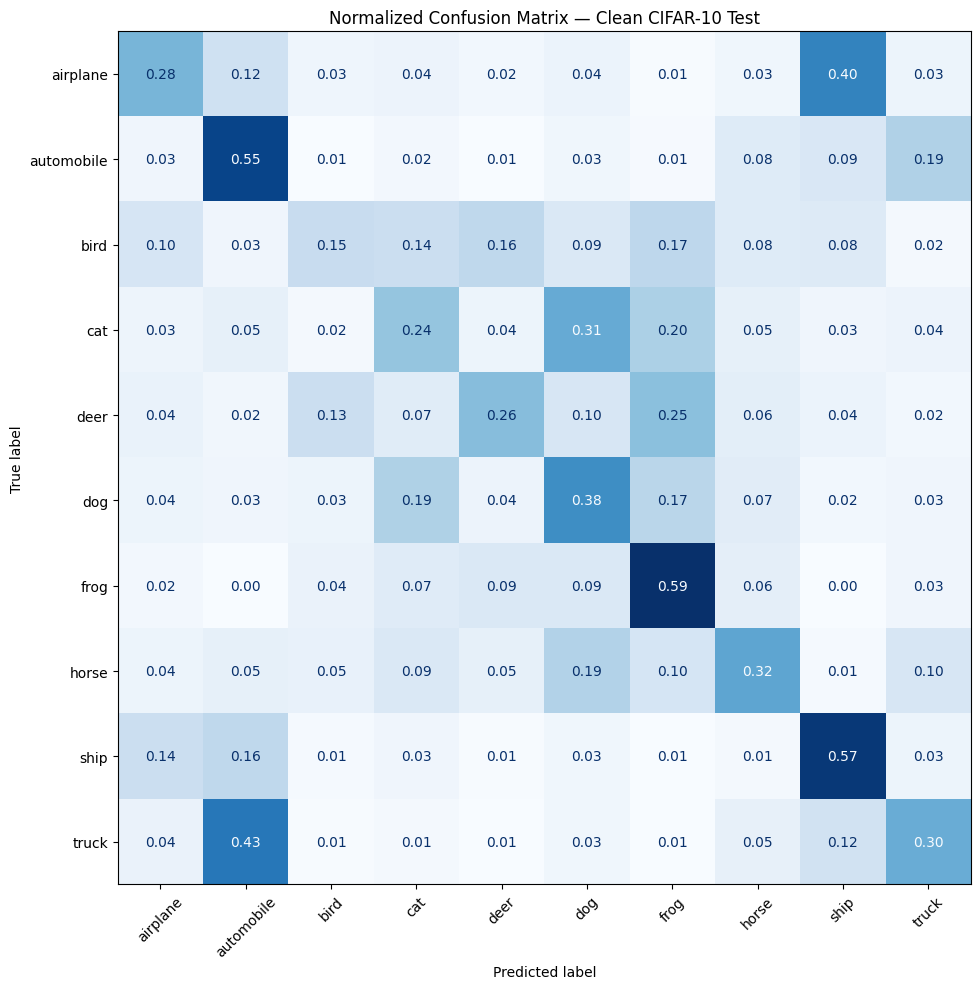

In [43]:

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

final_model.eval()
all_preds = []
all_labels = []
all_images = []

with torch.no_grad():
    for images, labels in clean_test_loader:
        images_device = images.to(device)
        outputs = final_model(images_device)
        preds = outputs.argmax(dim=1).cpu()

        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())
        all_images.extend(images.cpu())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

print("Clean test accuracy:",
      f"{100 * np.mean(all_preds == all_labels):.2f}%")

print("\nPer-class accuracy:")
for class_id, class_name in enumerate(class_names):
    mask = all_labels == class_id
    acc = 100 * np.mean(all_preds[mask] == all_labels[mask])
    print(f"{class_name:12s}: {acc:.2f}%")

cm = confusion_matrix(
    all_labels, all_preds,
    labels=list(range(len(class_names))),
    normalize="true"
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45,
    colorbar=False
)
plt.title("Normalized Confusion Matrix — Clean CIFAR-10 Test")
plt.tight_layout()
plt.show()



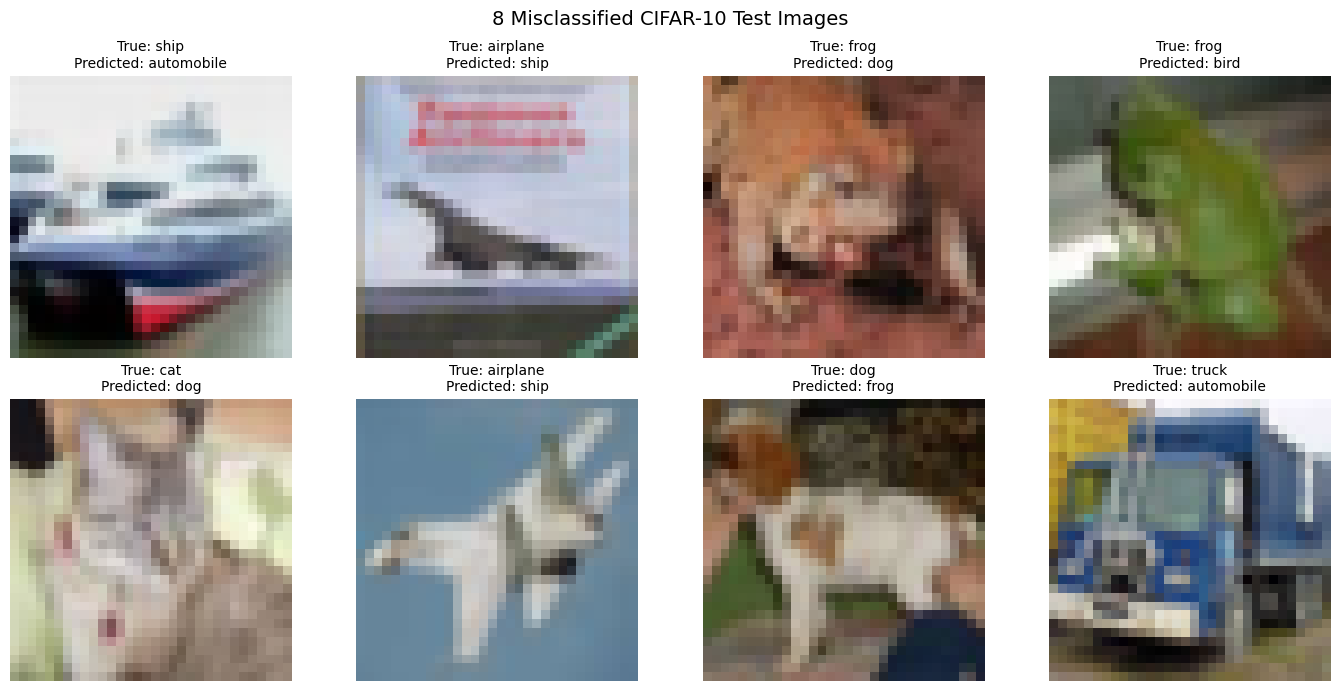

In [44]:

import matplotlib.pyplot as plt
import numpy as np

wrong_indices = np.where(all_preds != all_labels)[0]
num_images = min(8, len(wrong_indices))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for plot_i, data_i in enumerate(wrong_indices[:num_images]):
    image = all_images[data_i].permute(1, 2, 0).numpy()

    true_label = class_names[all_labels[data_i]]
    predicted_label = class_names[all_preds[data_i]]

    axes[plot_i].imshow(np.clip(image, 0, 1))
    axes[plot_i].set_title(
        f"True: {true_label}\nPredicted: {predicted_label}",
        fontsize=10
    )
    axes[plot_i].axis("off")

for i in range(num_images, len(axes)):
    axes[i].axis("off")

plt.suptitle("8 Misclassified CIFAR-10 Test Images", fontsize=14)
plt.tight_layout()
plt.show()


In [45]:

import torch
import numpy as np
from torch.utils.data import DataLoader, TensorDataset

# Reproducible corruption
torch.manual_seed(42)

# clean_test_loader uses images normalized to [0, 1]
clean_images = []
clean_labels = []

for images, labels in clean_test_loader:
    clean_images.append(images)
    clean_labels.append(labels)

X_clean = torch.cat(clean_images)
y_clean = torch.cat(clean_labels)

# Add Gaussian noise and keep pixel values in [0, 1]
noise = torch.randn(X_clean.shape) * 0.15
X_noisy = torch.clamp(X_clean + noise, 0.0, 1.0)

noisy_dataset = TensorDataset(X_noisy, y_clean)
noisy_loader = DataLoader(
    noisy_dataset, batch_size=128, shuffle=False
)

# Evaluate model on corrupted images
noisy_accuracy = evaluate_loader(final_model, noisy_loader)

print(f"Clean test accuracy: {100 * np.mean(all_preds == all_labels):.2f}%")
print(f"Gaussian-noise proxy accuracy: {noisy_accuracy:.2f}%")
print("\nNote: This is a self-generated corruption proxy,")
print("not the instructor's official shifted_test dataset.")


Clean test accuracy: 36.29%
Gaussian-noise proxy accuracy: 12.81%

Note: This is a self-generated corruption proxy,
not the instructor's official shifted_test dataset.


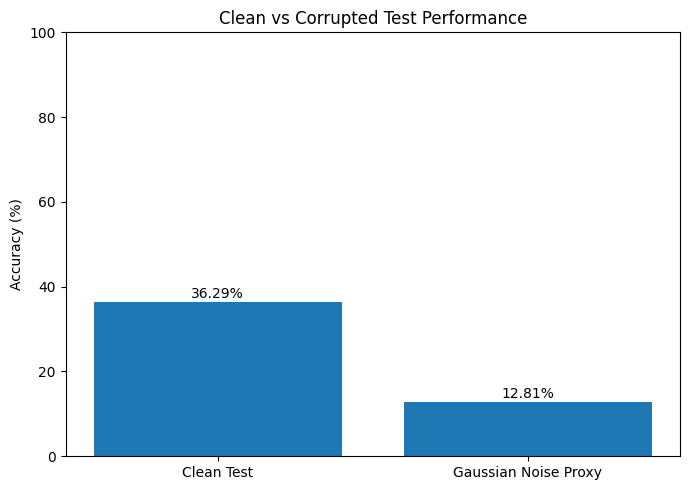

Accuracy change: -23.48 percentage points


In [46]:

import matplotlib.pyplot as plt

clean_acc = 100 * np.mean(all_preds == all_labels)

labels = ["Clean Test", "Gaussian Noise Proxy"]
accuracies = [clean_acc, noisy_accuracy]

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, accuracies)

plt.ylabel("Accuracy (%)")
plt.title("Clean vs Corrupted Test Performance")
plt.ylim(0, 100)

for bar, acc in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{acc:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

print(f"Accuracy change: {noisy_accuracy - clean_acc:+.2f} percentage points")


In [47]:

import numpy as np

# cm was normalized row-wise in Cell 38
confusion_scores = []

for true_id in range(len(class_names)):
    for pred_id in range(len(class_names)):
        if true_id != pred_id:
            confusion_scores.append({
                "True Class": class_names[true_id],
                "Predicted As": class_names[pred_id],
                "Confusion Rate (%)": cm[true_id, pred_id] * 100
            })

confusion_scores.sort(
    key=lambda item: item["Confusion Rate (%)"],
    reverse=True
)

print("TOP 5 CLASS CONFUSIONS")
for item in confusion_scores[:5]:
    print(
        f"{item['True Class']} -> {item['Predicted As']}: "
        f"{item['Confusion Rate (%)']:.2f}%"
    )


TOP 5 CLASS CONFUSIONS
truck -> automobile: 43.00%
airplane -> ship: 40.20%
cat -> dog: 30.60%
deer -> frog: 25.00%
cat -> frog: 19.90%


### Evaluation and Error Analysis

The final candidate model achieved **36.29% clean-test accuracy** on CIFAR-10. The per-class results show that the model performed best on *frog* (59.20%), followed by *ship* (57.20%) and *automobile* (54.50%). The lowest accuracy was observed for *bird* (14.60%), followed by *cat* (23.80%).

The normalized confusion matrix revealed several notable classification errors:

- **Truck → Automobile (43.00%):** Both classes have similar shapes and visual features, which may make them difficult to distinguish at low image resolution.
- **Airplane → Ship (40.20%):** Small images and limited training examples may make the visual features of these classes harder to identify reliably.
- **Cat → Dog (30.60%):** These classes share similar body shapes and textures.
- **Deer → Frog (25.00%) and Cat → Frog (19.90%):** These errors may reflect weak feature learning caused by the very small training dataset.

The model's performance also decreased by **23.48 percentage points** under the self-generated Gaussian-noise corruption test. This suggests sensitivity to noisy inputs. However, this experiment is a proxy evaluation and does not replace the instructor's official shifted-test dataset.

Overall, the results suggest that the limited training set of 400 images restricts generalization. The class-wise results, confusion matrix, and eight misclassified examples provide complementary evidence of the model's strengths and weaknesses.

In [49]:

import torch
import numpy as np

final_model.eval()
tta_predictions = []
tta_labels = []

with torch.no_grad():
    for images, labels in clean_test_loader:
        images = images.to(device)

        # Original predictions
        original_logits = final_model(images)

        # Horizontally flipped predictions
        flipped_images = torch.flip(images, dims=[3])
        flipped_logits = final_model(flipped_images)

        # Average both predictions
        avg_logits = (original_logits + flipped_logits) / 2
        predictions = avg_logits.argmax(dim=1).cpu()

        tta_predictions.extend(predictions.numpy())
        tta_labels.extend(labels.numpy())

tta_accuracy = 100 * np.mean(
    np.array(tta_predictions) == np.array(tta_labels)
)

normal_accuracy = 100 * np.mean(
    np.array(all_preds) == np.array(all_labels)
)

print(f"Normal accuracy: {normal_accuracy:.2f}%")
print(f"TTA accuracy: {tta_accuracy:.2f}%")
print(f"Improvement: {tta_accuracy - normal_accuracy:+.2f} percentage points")


Normal accuracy: 36.29%
TTA accuracy: 36.31%
Improvement: +0.02 percentage points
